# Dannyl MOUHEB – Modèle churn ClientCo – 3. Liste tous les mois ou toutes les 2 semaines ?

**Méthode** : on rejoue le processus réel sur la fenêtre de test (1er février → ~25 mars 2024), à **nombre total d'appels égal** :
- **Mensuel** : une liste le 1er de chaque mois ;
- **Bimensuel** : une liste le 1er et le 15, deux fois plus petite ;
- **Bimensuel (modèle mensuel)** : même calendrier, mais avec le modèle appris en mensuel, pour séparer l'effet « scorer plus souvent » de l'effet « apprendre sur plus de photos ».

Un client n'est appelé qu'une fois dans la fenêtre. Mêmes clients de test que le notebook 1 (20 %, jamais vus).

**Indicateurs** : vrais départs atteints, précision, part du CA à risque capté, marge annuelle maximale (groupe), **silence du client au moment de l'appel** (plus c'est court, plus on l'appelle tôt).

In [1]:
# --- Mise en place (ne pas modifier) -------------------------------------------------------------
# Le notebook se place à la racine du dépôt (où se trouve data/) et rend importables les modules
# du dossier dannyl_modele_churn.
import os, sys, json
import pandas as pd
from IPython.display import Image, display
if os.path.basename(os.getcwd()) == "dannyl_modele_churn":
    os.chdir("..")
sys.path.insert(0, os.path.abspath("dannyl_modele_churn"))
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
RES = os.path.join("dannyl_modele_churn", "resultats")
print("Dossier de travail :", os.getcwd())

Dossier de travail : c:\Users\DanXVI\Desktop\CentraleSupélec\3A\M2AD\EDC 3\case_BCGX


In [2]:
CONTACTS_PAR_MOIS = 20

In [3]:
import importlib, dannyl_3_comparaison_mensuel_bimensuel as script
importlib.reload(script)
sys.argv = ["dannyl_3_comparaison_mensuel_bimensuel"] + ["--contacts-par-mois", str(CONTACTS_PAR_MOIS)]
script.main()

Cache trouvé : c:\Users\DanXVI\Desktop\CentraleSupélec\3A\M2AD\EDC 3\case_BCGX\dannyl_modele_churn\cache\agregats.pkl
Apprentissage 2023-10-01 -> 2024-01-15 | test 2024-02-01 -> 2024-03-26

== Mensuel (1er du mois) : 4 photos d'apprentissage, 2 listes de test ==

== Bimensuel (1er et 15) : 8 photos d'apprentissage, 4 listes de test ==

== Bimensuel, modèle appris en mensuel ==

                  frequence                                   methode  contacts  vrais_departs  precision  part_perte_captee  marge_max_an_groupe_meur  silence_median_au_contact_j
     Mensuel (1er du mois)               Gradient boosting (XGBoost)       468            225      0.481              0.308                     273.2                         17.0
     Mensuel (1er du mois) Règle métier (silence vs rythme habituel)       468            194      0.415              0.230                     204.2                         36.0
     Bimensuel (1er et 15)               Gradient boosting (XGBoost)       468   

## Résultats

,frequence,methode,photos_apprentissage,listes_test,clients_par_liste,contacts,vrais_departs,precision,part_perte_captee,silence_median_au_contact_j,silence_relatif_median,ca_risque_contacte_an_groupe_meur,marge_max_an_groupe_meur
0,Mensuel (1er du mois),Gradient boosting (XGBoost),4,2,234,468,225,0.481,0.308,17.0,4.500000,1106.0,273.2
1,Mensuel (1er du mois),Règle métier (silence vs rythme habituel),4,2,234,468,194,0.415,0.230,36.0,11.666667,827.0,204.2
2,Bimensuel (1er et 15),Gradient boosting (XGBoost),8,4,117,468,229,0.489,0.240,16.0,4.000000,1056.0,260.9
3,Bimensuel (1er et 15),Règle métier (silence vs rythme habituel),8,4,117,468,207,0.442,0.200,36.0,12.000000,882.0,217.9
4,Bimensuel (modèle mensuel),Gradient boosting (XGBoost),0,4,117,468,211,0.451,0.232,16.0,4.266667,1021.0,252.3
5,Bimensuel (modèle mensuel),Règle métier (silence vs rythme habituel),0,4,117,468,207,0.442,0.200,36.0,12.000000,882.0,217.9


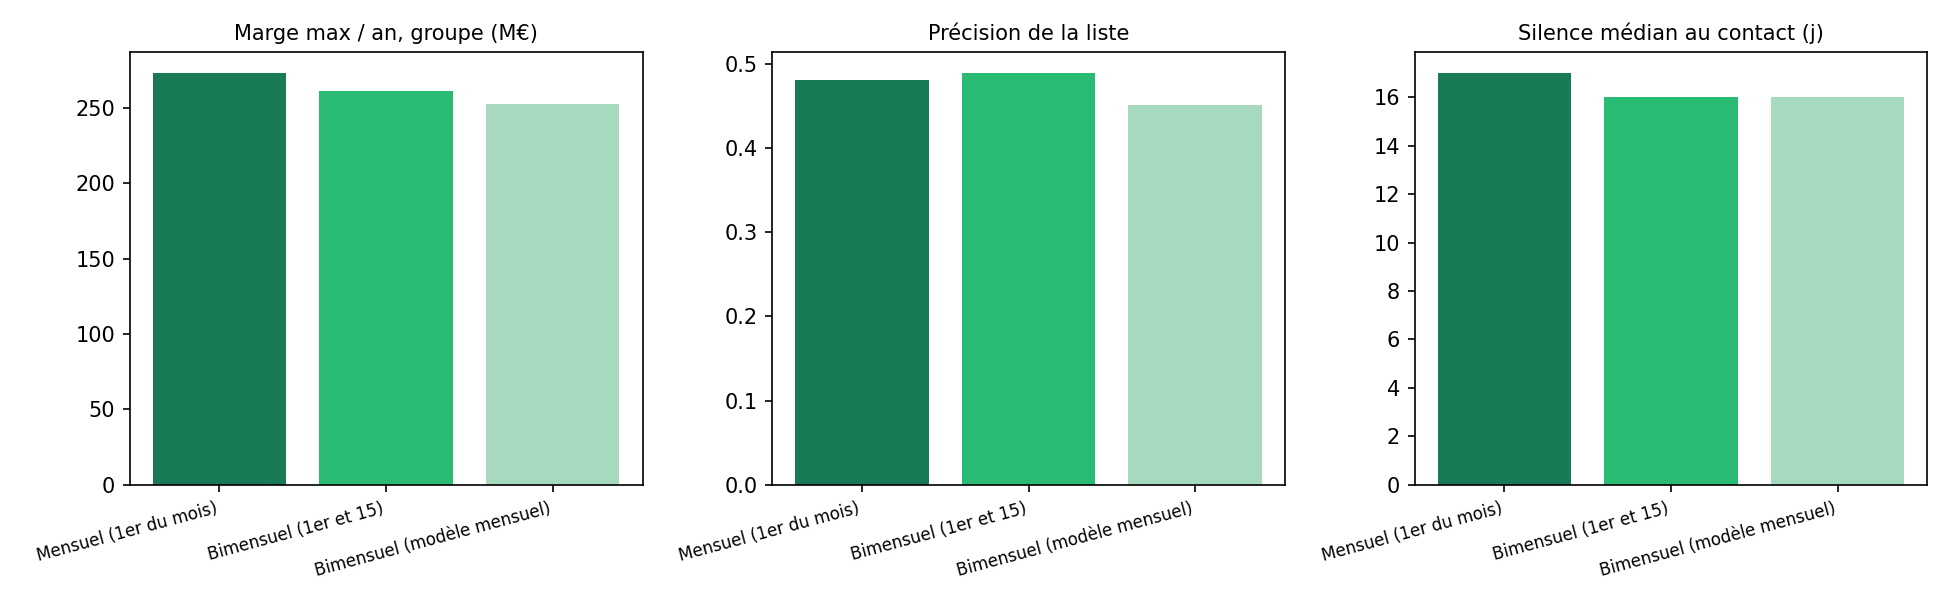

In [4]:
T = pd.read_csv(os.path.join(RES, "frequences", "comparaison_mensuel_bimensuel.csv"), sep=";")
display(T)
display(Image(os.path.join(RES, "frequences", "comparaison_mensuel_bimensuel.png")))